In [1]:
import pandas as pd

df = pd.read_csv("../data/llm_requests.csv")

print(df.shape)
print(df.info())
print(df.head())
print(df.isnull().sum())

(500, 6)
<class 'pandas.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 6 columns):
 #   Column               Non-Null Count  Dtype
---  ------               --------------  -----
 0   model                500 non-null    str  
 1   input_tokens         500 non-null    int64
 2   output_tokens        500 non-null    int64
 3   concurrent_requests  500 non-null    int64
 4   region               500 non-null    str  
 5   latency_ms           500 non-null    int64
dtypes: int64(4), str(2)
memory usage: 23.6 KB
None
   model  input_tokens  output_tokens  concurrent_requests   region  \
0  large           202            809                    5  us-east   
1  small          3116            154                    9  us-east   
2  large           230             80                    2  us-west   
3  small          2565             77                    9  eu-west   
4  large          2972            608                    7  eu-west   

   latency_ms  
0        2836  
1  

In [8]:
numeric_features = [
    "input_tokens",
    "output_tokens",
    "concurrent_requests"
]

categorical_features = [
    "model",
    "region"
]

X = df[numeric_features + categorical_features]

print(X.shape)

(500, 5)


In [20]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import (
    StandardScaler,
    OneHotEncoder
)

preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numeric_features),
        ("cat", OneHotEncoder(
            handle_unknown="ignore",
            sparse_output=False
        ), categorical_features)
    ]
)

X_processed = preprocessor.fit_transform(X)

print("Original shape:", X.shape)
print("Processed shape:", X_processed.shape)

Original shape: (500, 5)
Processed shape: (500, 9)


In [22]:
import numpy as np

print("Means:")
print(preprocessor.named_transformers_["num"].mean_)

print("Scales:")
print(preprocessor.named_transformers_["num"].scale_)

print("Processed means:")
print(np.mean(X_processed[:, :3], axis=0))

print("Processed std:")
print(np.std(X_processed[:, :3], axis=0))

Means:
[2049.906  534.558    5.85 ]
Scales:
[1146.08412831  267.63575739    2.84385302]
Processed means:
[3.88578059e-17 5.57331958e-17 1.05693232e-16]
Processed std:
[1. 1. 1.]


In [31]:
print("Original shape:", X.shape)
print("Processd shape:", X_processed.shape)

print(preprocessor.get_feature_names_out())

Original shape: (500, 5)
Processd shape: (500, 9)
['num__input_tokens' 'num__output_tokens' 'num__concurrent_requests'
 'cat__model_large' 'cat__model_medium' 'cat__model_small'
 'cat__region_eu-west' 'cat__region_us-east' 'cat__region_us-west']


In [33]:
from sklearn.cluster import KMeans

kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

kmeans.fit(X_processed)

print("Cluster labels:")
print(kmeans.labels_[:20])

print("Cluster centers:")
print(kmeans.cluster_centers_)

print("Inertia:")
print(kmeans.inertia_)

Cluster labels:
[2 0 2 0 0 2 2 2 2 1 1 0 2 1 2 2 1 0 0 1]
Cluster centers:
[[ 1.08730661 -0.26969292 -0.18763833  0.3220339   0.36723164  0.31073446
   0.32768362  0.3559322   0.31638418]
 [-0.48350407  0.47880092  0.89627572  0.34831461  0.35955056  0.29213483
   0.3258427   0.33146067  0.34269663]
 [-0.73372101 -0.25855805 -0.87120754  0.31724138  0.34482759  0.33793103
   0.40689655  0.31034483  0.28275862]]
Inertia:
1512.8421553210983


In [39]:
df_clustered = df.copy()

df_clustered["cluster"] = kmeans.labels_

print(
    df_clustered["cluster"]
    .value_counts()
    .sort_index()
)

cluster
0    177
1    178
2    145
Name: count, dtype: int64


In [45]:
cluster_profiles = (
    df_clustered
    .groupby("cluster")
    .agg(
        requests=("cluster", "size"),
        avg_input_tokens=("input_tokens", "mean"),
        avg_output_tokens=("output_tokens", "mean"),
        avg_concurrency=("concurrent_requests", "mean"),
        avg_latency_ms=("latency_ms","mean")
    )
    .round(2)
)

print(cluster_profiles)

         requests  avg_input_tokens  avg_output_tokens  avg_concurrency  \
cluster                                                                   
0             177           3296.05             462.38             5.32   
1             178           1495.77             662.70             8.40   
2             145           1209.00             465.36             3.37   

         avg_latency_ms  
cluster                  
0               2714.84  
1               2933.49  
2               2111.85  


In [48]:
inertias = []

k_values = range(1,9)

for k in k_values:
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    model.fit(X_processed)
    inertias.append(model.inertia_)

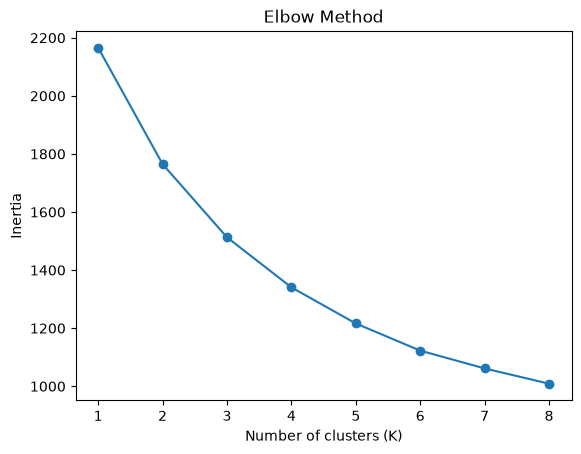

In [50]:
import matplotlib.pyplot as plt

plt.plot(k_values, inertias, marker="o")
plt.xlabel("Number of clusters (K)")
plt.ylabel("Inertia")
plt.title("Elbow Method")
plt.show()

In [54]:
from sklearn.metrics import silhouette_score

results = []

for k in range(2,9):
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = model.fit_predict(X_processed)

    score = silhouette_score(
        X_processed,
        labels
    )

    results.append({
        "k":k,
        "inertia": model.inertia_,
        "silhouette": score
    })

results_df = pd.DataFrame(results)
print(results_df)

   k      inertia  silhouette
0  2  1764.954107    0.174328
1  3  1512.842155    0.168306
2  4  1340.569239    0.173901
3  5  1216.160824    0.170430
4  6  1122.731041    0.168816
5  7  1061.390638    0.153659
6  8  1008.846716    0.145161


In [56]:
print(
    pd.crosstab(
        df_clustered["cluster"],
        df_clustered["model"],
        normalize="index"
    ).round(3)
)

print(
    pd.crosstab(
        df_clustered["cluster"],
        df_clustered["region"],
        normalize="index"
    ).round(3)
)

model    large  medium  small
cluster                      
0        0.322   0.367  0.311
1        0.348   0.360  0.292
2        0.317   0.345  0.338
region   eu-west  us-east  us-west
cluster                           
0          0.328    0.356    0.316
1          0.326    0.331    0.343
2          0.407    0.310    0.283


In [62]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

numeric_features = [
    "input_tokens",
    "output_tokens",
    "concurrent_requests"
]

X_numeric = df[numeric_features]

scaler = StandardScaler()
X_numeric_scaled = scaler.fit_transform(X_numeric)

results_numeric = []

for k in range(2,9):
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = model.fit_predict(X_numeric_scaled)

    results_numeric.append({
        "k": k,
        "inertia": model.inertia_,
        "silhouette": silhouette_score(
            X_numeric_scaled,
            labels
        )
    })

print(pd.DataFrame(results_numeric))

   k      inertia  silhouette
0  2  1099.941823    0.260783
1  3   846.133496    0.273075
2  4   675.559902    0.291173
3  5   558.760668    0.299643
4  6   466.661730    0.308580
5  7   403.907760    0.302525
6  8   356.077977    0.291113


In [68]:
from sklearn.cluster import KMeans

kmeans_6 = KMeans(
    n_clusters=6,
    random_state=42,
    n_init=10
)

label_6 = kmeans_6.fit_predict(X_numeric_scaled)

df_k6 = df.copy()
df_k6["cluster"] = label_6

print(df_k6["cluster"].value_counts().sort_index())

cluster
0     86
1     89
2    115
3     62
4     74
5     74
Name: count, dtype: int64


In [86]:
profiles_k6 = (
    df_k6.groupby("cluster")
    .agg(
        request=("cluster", "size"),
        avg_input_tokens=("input_tokens", "mean"),
        avg_output_tokens=("output_tokens", "mean"),
        avg_concurrency=("concurrent_requests", "mean"),
        avg_latency_ms=("latency_ms", "mean")
    )
    .round(2)
)

print(profiles_k6)

         request  avg_input_tokens  avg_output_tokens  avg_concurrency  \
cluster                                                                  
0             86           2924.13             331.81             2.94   
1             89           1018.42             275.71             6.38   
2            115           1352.57             741.47             8.43   
3             62           3108.21             299.53             8.21   
4             74           3388.27             779.41             5.81   
5             74           1133.15             712.01             2.65   

         avg_latency_ms  
cluster                  
0               2246.72  
1               2201.64  
2               3003.30  
3               2739.74  
4               3189.34  
5               2276.86  


In [76]:
kmeans_6.cluster_centers_

array([[ 0.76279034, -0.75753722, -1.02260543],
       [-0.9000127 , -0.96717321,  0.18707805],
       [-0.60845514,  0.77310882,  0.90584392],
       [ 0.92340837, -0.87815524,  0.82974662],
       [ 1.1677714 ,  0.91485311, -0.01378031],
       [-0.79990406,  0.6630486 , -1.12570914]])

In [82]:
centers_original = scaler.inverse_transform(
    kmeans_6.cluster_centers_
)

centers_df = pd.DataFrame(
    centers_original,
    columns=numeric_features
)

centers_df.index.name = "cluster"

print(centers_df.round(2))

         input_tokens  output_tokens  concurrent_requests
cluster                                                  
0             2924.13         331.81                 2.94
1             1018.42         275.71                 6.38
2             1352.57         741.47                 8.43
3             3108.21         299.53                 8.21
4             3388.27         779.41                 5.81
5             1133.15         712.01                 2.65


In [94]:
from sklearn.metrics import silhouette_samples

sample_scores = silhouette_samples(
    X_numeric_scaled,
    label_6
)

df_k6["silhouette"] = sample_scores

silhouette_by_cluster = (
    df_k6.groupby("cluster")["silhouette"]
    .agg(["mean", "min", "max", "count"])
    .round(3)
)

print(silhouette_by_cluster)

print(
    "Negative silhouette requests:",
    (sample_scores < 0).sum()
)

          mean    min    max  count
cluster                            
0        0.257  0.000  0.524     86
1        0.269 -0.043  0.541     89
2        0.333 -0.001  0.587    115
3        0.380  0.068  0.597     62
4        0.310 -0.040  0.564     74
5        0.317  0.029  0.571     74
Negative silhouette requests: 11


In [100]:
from sklearn.decomposition import PCA

pca = PCA(n_components = 2)

X_pca = pca.fit_transform(X_numeric_scaled)

print("Original shape:", X_numeric_scaled.shape)
print("PCA shape:", X_pca.shape)

Original shape: (500, 3)
PCA shape: (500, 2)


In [106]:
print("Explanied variance ratio:")
print(pca.explained_variance_ratio_)

print("Total explanied variance:")
print(pca.explained_variance_ratio_.sum())

Explanied variance ratio:
[0.36985021 0.3187398 ]
Total explanied variance:
0.6885900123735593


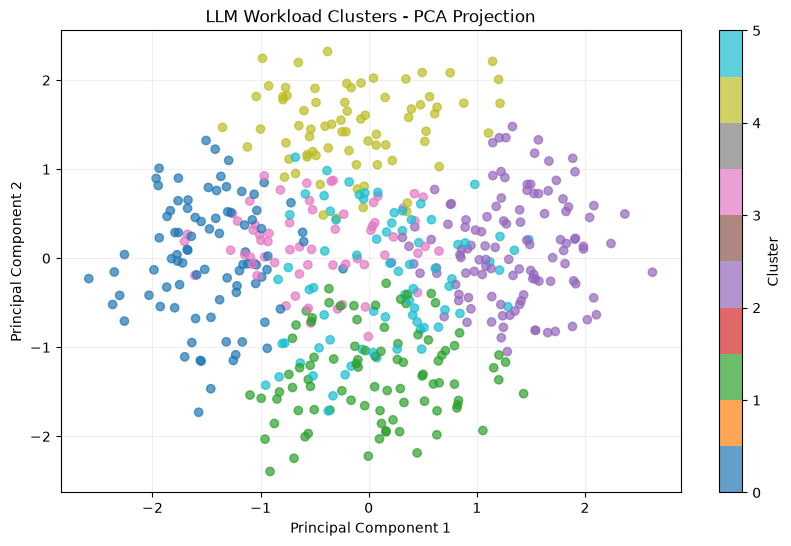

In [118]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

scatter = plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=label_6,
    cmap="tab10",
    alpha=0.7
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("LLM Workload Clusters - PCA Projection")

plt.colorbar(scatter, label="Cluster")
plt.grid(alpha=0.2)
plt.show()


In [126]:
import pandas as pd

components_df = pd.DataFrame(
    pca.components_,
    columns=numeric_features,
    index=["PC1", "PC2"]
)

print(components_df.round(3))

     input_tokens  output_tokens  concurrent_requests
PC1        -0.552          0.566                0.612
PC2         0.747          0.662                0.062


In [128]:
from sklearn.metrics import silhouette_score

original_score = silhouette_score(
    X_numeric_scaled,
    label_6
)

projected_score = silhouette_score(
    X_pca,
    label_6
)

print("Original 3D Silhouette:", original_score)
print("Projected 2D Silhouette:", projected_score)

Original 3D Silhouette: 0.3085801963709323
Projected 2D Silhouette: 0.1869655162610751


In [132]:
import numpy as np

from sklearn.metrics.pairwise import (
    cosine_similarity,
    euclidean_distances
)

A = np.array([[3.0, 4.0]])
B = np.array([[6.0, 8.0]])

euclidean = euclidean_distances(A, B)[0, 0]
dot_product = np.dot(A[0], B[0])
cosine = cosine_similarity(A, B)[0, 0]

print("Euclidean distance:", euclidean)
print("Dot product:", dot_product)
print("Cosine similarity", cosine)

Euclidean distance: 5.0
Dot product: 50.0
Cosine similarity 1.0


In [138]:
from sklearn.preprocessing import Normalizer

normalizer = Normalizer(norm="l2")

A_normalized = normalizer.transform(A)
B_normalized = normalizer.transform(B)

print(A_normalized)
print(B_normalized)

print(
    "Normalized dot product:",
    np.dot(A_normalized[0], B_normalized[0])
)


[[0.6 0.8]]
[[0.6 0.8]]
Normalized dot product: 1.0
